# Mini-Project 5 – Taxi Route Revenue, Pricing & Fleet Planner

**OOP with Python, Assignment 1 (Advent 2026)** · Wesonga John Collins

A matatu association runs 14-seater vehicles on three routes out of Kampala. This notebook analyses route
revenue, finds the fare equilibrium on the Ntinda route, compares three forecasters by walk-forward
backtesting, forecasts day 11 and sizes the fleet.

Reusable logic lives in `src/a1/taxi_routes.py` and the shared `src/a1/forecasting.py` (the same `Forecaster`
base class as Mini-Project 1), unit-tested in `tests/`.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from a1.forecasting import (
    LinearTrendForecaster,
    MovingAverageForecaster,
    SeasonalNaiveForecaster,
    SESForecaster,
    walk_forward,
)
from a1.metrics import mae
from a1.taxi_routes import (
    WEEKDAY_FACTORS,
    LinearMarket,
    Route,
    simulate_weekly_demand,
    tune_ses_alpha,
    vehicles_needed,
    walk_forward_mae,
)

SEED = 2026                 # single seed for the simulation extension
FIRST_TARGET_DAY = 4        # walk-forward evaluation over days 4-10
TRIPS_PER_DAY, SEATS, BUFFER = 8, 14, 0.15
pd.set_option("display.precision", 3)

## 1. Data

Daily passenger counts over 10 days (Ntinda figures from the original question; Entebbe and Mukono
illustrative, as given in the brief). Fares in UGX per passenger.

In [2]:
routes = {
    "Kampala-Ntinda": Route("Kampala-Ntinda", [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2000),
    "Kampala-Entebbe": Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5000),
    "Kampala-Mukono": Route("Kampala-Mukono", [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3000),
}
pd.DataFrame({name: r.passengers for name, r in routes.items()},
             index=pd.Index(range(1, 11), name="day")).astype(int)

,Kampala-Ntinda,Kampala-Entebbe,Kampala-Mukono
day,,,
1,35,60,45
2,40,58,47
3,42,65,50
4,50,70,49
5,55,72,55
6,60,80,62
7,48,75,58
8,52,68,53
9,47,66,51


## 2. Task 1 – the `Route` class: revenue and descriptive statistics

`Route` stores the counts as a read-only NumPy array plus the fare, validates both, and provides
`daily_revenue()`, `total_revenue()` and `stats()` (mean, median, sample variance and standard deviation
via the `statistics` module).

In [3]:
for r in routes.values():
    print(repr(r), "| len =", len(r))

try:
    Route("Bad route", [40, -3, 45], 2000)
except ValueError as err:
    print("Rejected (negative count):", err)

revenue = pd.DataFrame({name: r.daily_revenue() for name, r in routes.items()},
                       index=pd.Index(range(1, 11), name="day"))
display((revenue / 1000).astype(int).rename(columns=lambda c: f"{c} (UGX '000)"))

summary = pd.DataFrame({
    name: {**r.stats(), "fare (UGX)": r.fare, "total revenue (UGX)": r.total_revenue(),
           "CV of passengers (%)": r.stats()["stdev"] / r.stats()["mean"] * 100}
    for name, r in routes.items()
}).T
# Hand check: Ntinda carried 474 passengers at UGX 2,000.
assert routes["Kampala-Ntinda"].total_revenue() == 474 * 2000
summary

Route('Kampala-Ntinda', days=10, fare=UGX 2,000) | len = 10
Route('Kampala-Entebbe', days=10, fare=UGX 5,000) | len = 10
Route('Kampala-Mukono', days=10, fare=UGX 3,000) | len = 10
Rejected (negative count): passenger counts must not be negative


,Kampala-Ntinda (UGX '000),Kampala-Entebbe (UGX '000),Kampala-Mukono (UGX '000)
day,,,
1,70,300,135
2,80,290,141
3,84,325,150
4,100,350,147
5,110,360,165
6,120,400,186
7,96,375,174
8,104,340,159
9,94,330,153


,mean,median,variance,stdev,fare (UGX),total revenue (UGX),CV of passengers (%)
Kampala-Ntinda,47.4,47.5,54.267,7.367,2000.0,9.480e+05,15.541
Kampala-Entebbe,67.8,67.0,45.067,6.713,5000.0,3.390e+06,9.901
Kampala-Mukono,52.0,50.5,26.444,5.142,3000.0,1.560e+06,9.889


Kampala-Entebbe is the largest earner: UGX 3.39 million over ten days, about 57 % of the three routes' revenue, because it combines the highest fare (UGX 5,000) with the most passengers (mean 67.8 a day). Mukono earns UGX 1.56 million and Ntinda UGX 0.95 million. Ntinda is also the most variable route relative to its size (coefficient of variation 15.5 %, against about 9.9 % for the other two), so its revenue is the least predictable. On all three routes passenger numbers rise to a peak on day 6 and then fall back, which matters for the forecasting comparison below. The variances use `statistics.variance` (sample variance, dividing by n − 1) and are in passengers²; the standard deviations (5.1–7.4 passengers a day) are easier to interpret.

## 3. Task 2 – supply–demand equilibrium on the Ntinda route

Demand $Q_d = 120 - 0.02P$ and supply $Q_s = 10 + 0.03P$, with $P$ the fare in UGX and $Q$ passengers per
trip-hour. At equilibrium $Q_d = Q_s = Q$, which gives a 2×2 linear system in the unknowns $(P, Q)$:

$$\begin{pmatrix} 0.02 & 1 \\ -0.03 & 1 \end{pmatrix}\begin{pmatrix} P \\ Q \end{pmatrix}
= \begin{pmatrix} 120 \\ 10 \end{pmatrix}$$

In [4]:
market = LinearMarket(demand_intercept=120, demand_slope=0.02, supply_intercept=10, supply_slope=0.03)
A, b = market.system()
print("A =\n", A, "\nb =", b)
print(f"det(A) = {np.linalg.det(A):.4f}   cond(A) = {np.linalg.cond(A):.1f}")

p_star, q_star = market.equilibrium()          # scipy.linalg.solve
print(f"Equilibrium fare P* = UGX {p_star:,.0f};  quantity Q* = {q_star:.1f} passengers per trip-hour")

# Second-method check: substitute back into both equations, and solve by hand (110 = 0.05P).
assert np.allclose(A @ [p_star, q_star], b)
assert np.isclose(p_star, 110 / 0.05)

pd.DataFrame({
    fare: {"demand Qd": market.demand(fare), "supply Qs": market.supply(fare),
           "excess demand Qd - Qs": market.excess_demand(fare)}
    for fare in (2000, p_star)
}).T.rename_axis("fare (UGX)")

A =
 [[ 0.02  1.  ]
 [-0.03  1.  ]] 
b = [120  10]
det(A) = 0.0500   cond(A) = 40.0
Equilibrium fare P* = UGX 2,200;  quantity Q* = 76.0 passengers per trip-hour


,demand Qd,supply Qs,excess demand Qd - Qs
fare (UGX),,,
2000.0,80.0,70.0,10.0
2200.0,76.0,76.0,0.0


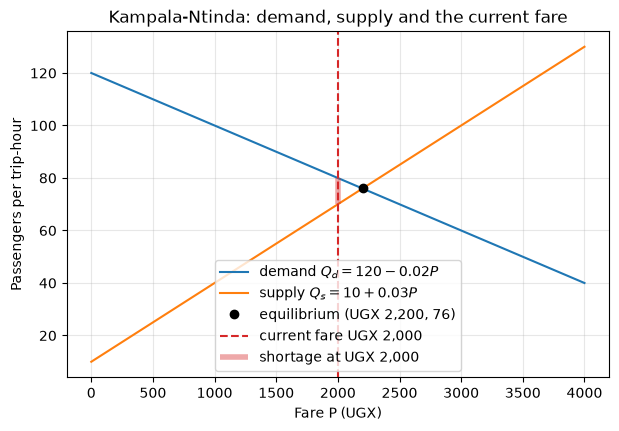

In [5]:
prices = np.linspace(0, 4000, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(prices, [market.demand(p) for p in prices], label="demand $Q_d = 120 - 0.02P$")
ax.plot(prices, [market.supply(p) for p in prices], label="supply $Q_s = 10 + 0.03P$")
ax.plot(p_star, q_star, "ko", label=f"equilibrium (UGX {p_star:,.0f}, {q_star:.0f})")
ax.axvline(2000, color="tab:red", ls="--", label="current fare UGX 2,000")
ax.vlines(2000, market.supply(2000), market.demand(2000), color="tab:red", lw=4, alpha=0.4,
          label="shortage at UGX 2,000")
ax.set_xlabel("Fare P (UGX)")
ax.set_ylabel("Passengers per trip-hour")
ax.set_title("Kampala-Ntinda: demand, supply and the current fare")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Solving the system gives an equilibrium fare of **UGX 2,200** with **76 passengers per trip-hour**; substituting back into both equations and the hand solution (110 = 0.05P) confirm it. The determinant (0.05) is non-zero and the condition number (40) is modest, so the system is well-posed. The current fare of UGX 2,000 is UGX 200 (about 9 %) **below** equilibrium: at that price 80 passengers per trip-hour want to travel but operators supply only 70, a shortage of 10 (12.5 % of demand unmet). In practice this appears as queues and overloading at the stage. Raising the fare towards UGX 2,200 would clear the market, but fares are sensitive for commuters; the alternative is more supply, which shifts the supply line to the right. The curves are given in the brief rather than estimated, and Q is passengers per trip-hour, so it cannot be compared directly with the daily counts.

## 4. Task 3 – forecasters

All forecasters subclass the shared abstract `Forecaster` (`fit(values)`, `predict(horizon)`):

* **3-day moving average** (the original method): forecast = mean of the last 3 days.
* **Simple exponential smoothing (SES)**: level $\ell_t = \alpha y_t + (1-\alpha)\ell_{t-1}$, starting from
  $\ell_1 = y_1$; forecast = final level. $\alpha$ is tunable; $\alpha = 1$ is the naive "same as yesterday".
* **Linear trend**: least-squares line through the history (`np.polyfit`), reused unchanged from Mini-Project 1.

## 5. Task 4 – walk-forward backtesting and tuning α

For each target day $t = 4, \dots, 10$, a fresh copy of the model is fitted on days $1, \dots, t-1$ **only**
and forecasts day $t$ (7 one-step forecasts per model per route). α is tuned per route by grid search over
0.05, 0.10, …, 1.00 using the same walk-forward MAE.

Best alpha per route: {'Kampala-Ntinda': 1.0, 'Kampala-Entebbe': 1.0, 'Kampala-Mukono': 1.0}


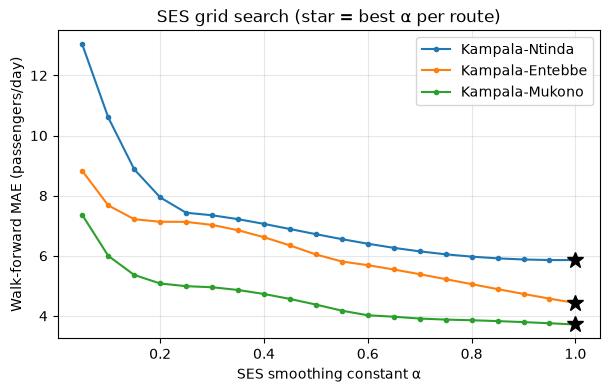

In [6]:
best_alpha, alpha_scores = {}, {}
for name, r in routes.items():
    best_alpha[name], alpha_scores[name] = tune_ses_alpha(r.passengers, first_target_day=FIRST_TARGET_DAY)

alpha_table = pd.DataFrame(alpha_scores).rename_axis("alpha")
print("Best alpha per route:", best_alpha)

fig, ax = plt.subplots(figsize=(7, 4))
for name in routes:
    ax.plot(alpha_table.index, alpha_table[name], marker=".", label=name)
    ax.plot(best_alpha[name], alpha_table.loc[best_alpha[name], name], "k*", ms=12)
ax.set_xlabel("SES smoothing constant α")
ax.set_ylabel("Walk-forward MAE (passengers/day)")
ax.set_title("SES grid search (star = best α per route)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [7]:
def models_for(route_name):
    return [MovingAverageForecaster(3),
            SESForecaster(best_alpha[route_name]),
            LinearTrendForecaster()]

mae_table = pd.DataFrame({
    name: {m.name if m.name != "SES" else f"SES (α={best_alpha[name]})":
           walk_forward_mae(m, r.passengers, FIRST_TARGET_DAY) for m in models_for(name)}
    for name, r in routes.items()
}).T
mae_table.columns = ["3-day moving average", "SES (tuned α)", "Linear trend"]
best_model = mae_table.idxmin(axis=1)

# Show the alpha used next to the MAE table, and the best model per route.
display(mae_table.assign(**{"tuned α": pd.Series(best_alpha), "best model": best_model}))

# Transparency: the individual walk-forward forecasts for Ntinda.
r = routes["Kampala-Ntinda"]
detail = {"actual": r.passengers[FIRST_TARGET_DAY - 1:]}
for m, label in zip(models_for(r.name), mae_table.columns):
    _, preds = walk_forward(m, r.passengers, FIRST_TARGET_DAY - 1)
    detail[label] = preds
pd.DataFrame(detail, index=pd.Index(range(FIRST_TARGET_DAY, 11), name="target day (Ntinda)"))

,3-day moving average,SES (tuned α),Linear trend,tuned α,best model
Kampala-Ntinda,7.524,5.857,7.873,1.0,SES (tuned α)
Kampala-Entebbe,7.190,4.429,7.711,1.0,SES (tuned α)
Kampala-Mukono,5.333,3.714,6.391,1.0,SES (tuned α)


,actual,3-day moving average,SES (tuned α),Linear trend
target day (Ntinda),,,,
4,50.0,39.000,42.0,46.000
5,55.0,44.000,50.0,53.500
6,60.0,49.000,55.0,59.400
7,48.0,55.000,60.0,64.800
8,52.0,54.333,48.0,60.286
9,47.0,53.333,52.0,59.429
10,45.0,49.000,47.0,56.500


On every route the grid search selects **α = 1.0**, the top of the grid, at which SES becomes the naive "same as yesterday" forecast. It has the lowest walk-forward MAE everywhere (5.9, 4.4 and 3.7 passengers a day for Ntinda, Entebbe and Mukono), against 5.3–7.5 for the 3-day moving average and 6.4–7.9 for the linear trend. The Ntinda detail shows why: all models miss the turning point after day 6, but the naive forecast recovers within a day, whereas the moving average keeps averaging in the busy days 5–6 and the linear trend keeps extrapolating the earlier rise (forecasting 56–60 passengers for days 8–10 when 45–52 travelled). With so few days, the most recent level is the best guide. Two caveats: α was tuned on the same seven days it is scored on, so the SES error is optimistic, and a best value at the edge of the grid means the data prefer no smoothing at all rather than identifying a well-defined α.

## 6. Task 5 – day-11 revenue forecast

The best model for each route is fitted on days 1–10 and forecasts day 11 passengers; revenue = forecast ×
fare. (With a constant fare, forecasting passengers and multiplying is identical to forecasting revenue
directly, because all three models scale linearly.)

In [8]:
label_to_model = {"3-day moving average": lambda n: MovingAverageForecaster(3),
                  "SES (tuned α)": lambda n: SESForecaster(best_alpha[n]),
                  "Linear trend": lambda n: LinearTrendForecaster()}

day11 = {}
for name, r in routes.items():
    model = label_to_model[best_model[name]](name).fit(r.passengers)
    passengers_11 = float(model.predict(1)[0])
    day11[name] = {"best model": best_model[name], "passengers day 11": passengers_11,
                   "fare (UGX)": r.fare, "revenue day 11 (UGX)": passengers_11 * r.fare}
day11_table = pd.DataFrame(day11).T
day11_table

,best model,passengers day 11,fare (UGX),revenue day 11 (UGX)
Kampala-Ntinda,SES (tuned α),45.0,2000.0,90000.0
Kampala-Entebbe,SES (tuned α),64.0,5000.0,320000.0
Kampala-Mukono,SES (tuned α),50.0,3000.0,150000.0


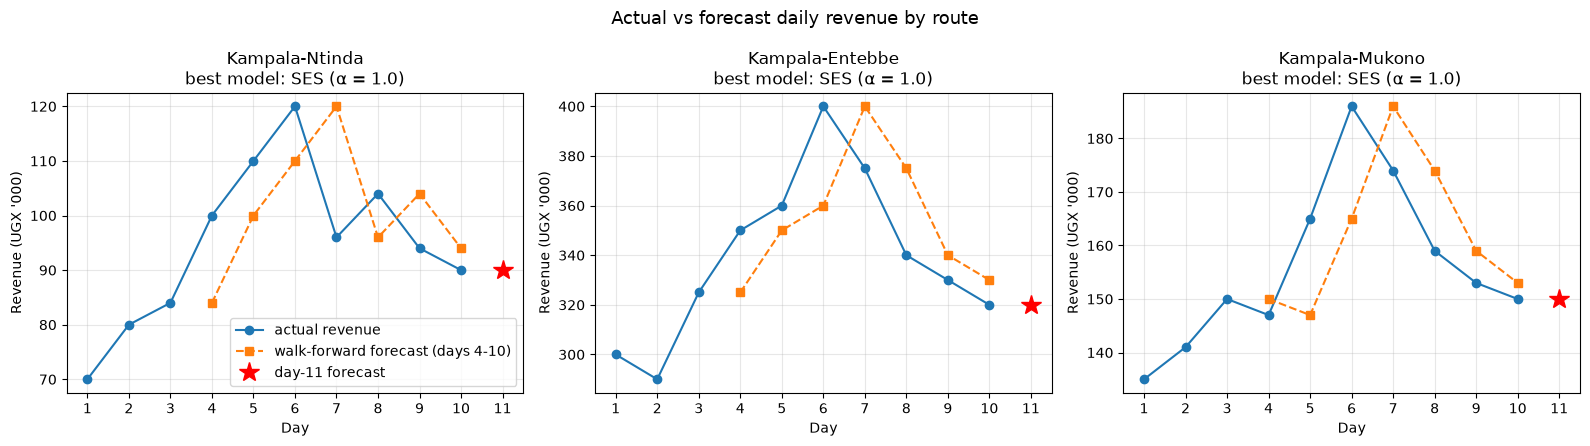

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
for ax, (name, r) in zip(axes, routes.items()):
    model = label_to_model[best_model[name]](name)
    targets, preds = walk_forward(model, r.passengers, FIRST_TARGET_DAY - 1)
    ax.plot(r.days, r.daily_revenue() / 1000, "o-", label="actual revenue")
    ax.plot(targets + 1, preds * r.fare / 1000, "s--", label="walk-forward forecast (days 4-10)")
    ax.plot(11, day11[name]["revenue day 11 (UGX)"] / 1000, "r*", ms=15, label="day-11 forecast")
    chosen = best_model[name].replace("tuned α", f"α = {best_alpha[name]}")
    ax.set_title(f"{name}\nbest model: {chosen}")
    ax.set_xlabel("Day")
    ax.set_ylabel("Revenue (UGX '000)")
    ax.set_xticks(range(1, 12))
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower right")
fig.suptitle("Actual vs forecast daily revenue by route", fontsize=13)
fig.tight_layout()
plt.show()

Because the best model is the naive forecast, day 11 is forecast to repeat day 10: 45 passengers on Ntinda (UGX 90,000), 64 on Entebbe (UGX 320,000) and 50 on Mukono (UGX 150,000), UGX 560,000 in total. The chart shows the price of this choice: the walk-forward forecasts are the actual series shifted one day to the right, so they always react a day late and miss the day-6 peak. The day-11 figures therefore assume the recent decline levels off; if it continues, they are slightly too high.

## 7. Task 6 – fleet planning for day 11

Each vehicle makes 8 one-way trips of 14 seats = 112 passenger-places per day.
Vehicles $= \lceil 1.15 \times \text{forecast passengers} / 112 \rceil$, with a minimum of one vehicle.

In [10]:
capacity = TRIPS_PER_DAY * SEATS
fleet = pd.DataFrame({
    name: {"forecast passengers": row["passengers day 11"],
           "with 15% buffer": row["passengers day 11"] * (1 + BUFFER),
           "places per vehicle": capacity,
           "vehicles (exact)": row["passengers day 11"] * (1 + BUFFER) / capacity,
           "vehicles to deploy": vehicles_needed(row["passengers day 11"], TRIPS_PER_DAY, SEATS, BUFFER),
           "seat utilisation (%)": row["passengers day 11"]
                                   / (vehicles_needed(row["passengers day 11"], TRIPS_PER_DAY, SEATS, BUFFER)
                                      * capacity) * 100}
    for name, row in day11.items()
}).T
fleet

,forecast passengers,with 15% buffer,places per vehicle,vehicles (exact),vehicles to deploy,seat utilisation (%)
Kampala-Ntinda,45.0,51.75,112.0,0.462,1.0,40.179
Kampala-Entebbe,64.0,73.60,112.0,0.657,1.0,57.143
Kampala-Mukono,50.0,57.50,112.0,0.513,1.0,44.643


Every route needs only **one** vehicle on day 11: even with the 15 % buffer, forecast demand is 46–66 % of a single vehicle's 112 daily places, and seat utilisation would be 40–57 %. The rounding rule (round up, minimum one) is therefore not the deciding factor; the small counts are. A real association runs many vehicles per route, which suggests the counts describe a sample (for example one vehicle, one stage or one direction) rather than total route demand. The calculation also spreads demand evenly over eight trips, whereas matatu demand concentrates in the morning and evening peaks, when one vehicle could be full while off-peak trips run nearly empty. Before using this for deployment, the association should confirm what the counts measure and plan capacity for the peak hour.

## 8. Extension – weekly pattern: seasonal naïve vs moving average

60 days are simulated with a seeded generator (day 1 = Monday) from an illustrative weekly pattern: busiest
on Friday, quietest on Sunday, plus noise. Both forecasters are scored by the same walk-forward method from
day 8 (the first day with a full previous week) to day 60.

In [11]:
rng = np.random.default_rng(SEED)
base = routes["Kampala-Ntinda"].stats()["mean"]          # scale the simulation to the Ntinda route
sim = simulate_weekly_demand(60, base, rng=rng)
weekdays = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Weekly factors:", dict(zip(weekdays, WEEKDAY_FACTORS)))
print("Mean simulated passengers by weekday:",
      pd.Series(sim).groupby(np.arange(60) % 7).mean().set_axis(weekdays).round(1).to_dict())

contenders = [MovingAverageForecaster(3), SeasonalNaiveForecaster(7)]
ext = {}
for m in contenders:
    targets, preds = walk_forward(m, sim, 7)              # targets: days 8..60
    ext[m.name] = {"MAE (passengers/day)": mae(sim[targets], preds), "forecasts": preds}
ext_table = pd.DataFrame({k: {"MAE (passengers/day)": v["MAE (passengers/day)"]} for k, v in ext.items()}).T
ext_table

Weekly factors: {'Mon': 1.0, 'Tue': 0.95, 'Wed': 1.0, 'Thu': 1.05, 'Fri': 1.35, 'Sat': 1.1, 'Sun': 0.65}
Mean simulated passengers by weekday: {'Mon': 48.0, 'Tue': 45.7, 'Wed': 46.9, 'Thu': 51.3, 'Fri': 67.0, 'Sat': 51.4, 'Sun': 31.4}


,MAE (passengers/day)
3-day moving average,8.818
Seasonal naive (7),3.075


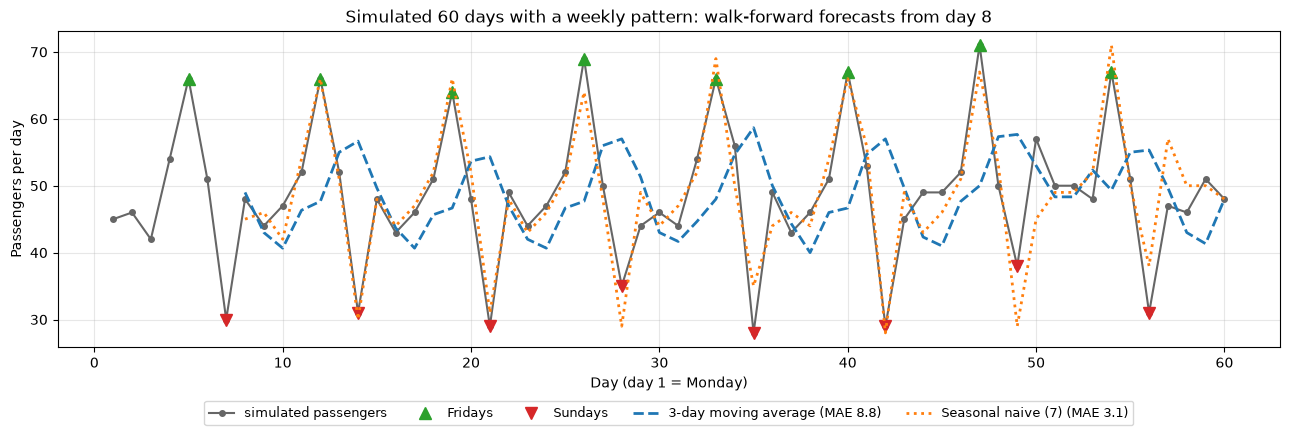

In [12]:
days = np.arange(1, 61)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(days, sim, "o-", color="0.4", ms=4, label="simulated passengers")
ax.plot(days[4::7], sim[4::7], "^", color="tab:green", ms=8, label="Fridays")
ax.plot(days[6::7], sim[6::7], "v", color="tab:red", ms=8, label="Sundays")
for name, style in zip(ext, ["--", ":"]):
    ax.plot(days[7:], ext[name]["forecasts"], style, lw=2,
            label=f"{name} (MAE {ext[name]['MAE (passengers/day)']:.1f})")
ax.set_xlabel("Day (day 1 = Monday)")
ax.set_ylabel("Passengers per day")
ax.set_title("Simulated 60 days with a weekly pattern: walk-forward forecasts from day 8")
ax.legend(ncol=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Over days 8–60 the seasonal naïve forecaster (repeat the same weekday from last week) has an MAE of 3.1 passengers a day against 8.8 for the 3-day moving average, about 65 % lower. The moving average blends neighbouring days with very different demand, so it is always late for the Friday peaks (simulated mean 67 passengers) and the Sunday troughs (31), as the chart shows. Seasonal naïve gets these right because the pattern repeats, and its remaining error is mostly day-to-day noise. The comparison is fair (same walk-forward rule, same days, fixed seed), but the outcome is partly built in: the data were generated from a weekly pattern chosen here, and seasonal naïve cannot adapt to trends, holidays or a changing pattern. In the brief's ten-day data the weekly cycle cannot even be observed.

## 9. Findings & Limitations

For the association, the main message is that demand on all three routes is small relative to vehicle capacity and that short-term forecasting is dominated by persistence. Entebbe earns the most (UGX 3.39 million over ten days, 57 % of all revenue) because of its higher fare and passenger numbers, while Ntinda carries the fewest passengers and is the most variable (CV 15.5 %). On Ntinda the current UGX 2,000 fare is below the equilibrium of UGX 2,200, leaving an estimated shortage of 10 passengers per trip-hour; a modest fare rise or extra supply at busy times would close it. In the backtest, simple exponential smoothing won on every route, but only because the tuned α reached 1.0, the same-as-yesterday forecast: every model missed the turning point after day 6, and the naive forecast recovered fastest. Day-11 demand is therefore forecast to equal day-10 demand, and every route needs only one vehicle, with spare capacity. The extension shows that when a weekly pattern is present, a seasonal naïve forecaster cuts the error by about two-thirds compared with the moving average.

These conclusions have clear limits. Ten days are far too few to estimate a trend or weekly seasonality, and α was tuned on the same seven days used to score it, so the SES error is optimistic. The Entebbe and Mukono data are illustrative, and the demand and supply equations are assumed rather than estimated. The fleet rule spreads daily demand evenly over eight trips, ignoring peak hours, and the counts may cover only one direction or one vehicle. Finally, the extension's weekly pattern was simulated with factors chosen here, so its result partly reflects that construction and should be confirmed on real data.